In [3]:
import numpy as np
ds= np.load("/home/s0shar47/scratch/BASEFLOW_FOLDS/1/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
)
ds.shape

(52, 12784, 16)

In [4]:
filepath= "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"

dd= np.load(filepath)
dd.shape

(671, 12784, 15)

In [7]:
import json

with open("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_name.json",'r') as f:
    data= json.load(f)
data


['Year',
 'Mnth',
 'Day',
 'Hr',
 'dayl(s)',
 'prcp(mm/day)',
 'srad(W/m2)',
 'swe(mm)',
 'tmax(C)',
 'tmin(C)',
 'vp(Pa)',
 'PEVAP',
 '00060_Mean',
 'tmean(C)',
 'gage_id']

In [8]:
import json

with open("/home/s0shar47/scratch/BASEFLOW_FOLDS/1/test/DAYMET_19800101_20141231_forcing_baseflow_mmday_name.json",'r') as f:
    data= json.load(f)
data


['Year',
 'Mnth',
 'Day',
 'Hr',
 'dayl(s)',
 'prcp(mm/day)',
 'srad(W/m2)',
 'swe(mm)',
 'tmax(C)',
 'tmin(C)',
 'vp(Pa)',
 'PEVAP',
 '00060_Mean',
 'tmean(C)',
 'gage_id',
 'baseflow']

In [ ]:
import numpy as np
import pandas as pd
import baseflow
import json

actions=['test','train']

for i in range(0,1):
    
# 1. Load your raw numpy arrays from your scratch path
        forcings_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"

        file_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_name.json"
        with open(file_path, "r") as f:
            data = json.load(f)

        # # append new entry
        data.append("baseflow")
        forcings = np.load(forcings_path, allow_pickle=True)

        attr= np.load(f"/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy", allow_pickle=True)
        # np.save(f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/daymet_19800101_20141231_attr_671.npy", attr)

        print("Original Forcings shape:", forcings.shape) 
        # Expecting (num_basins, num_timesteps, num_variables)

        num_basins = forcings.shape[0]
        num_timesteps = forcings.shape[1]

        # 2. Pre-allocate an empty array to temporarily hold the baseflow timeseries for all basins
        all_baseflows = np.zeros((num_basins, num_timesteps))

        # 3. Loop through every basin to compute the Furey-Gupta separation vector
        # We do this because baseflow.separation expects data arranged by basin column matrices
        for basin_idx in range(num_basins):
            # Extract streamflow vector for current basin (index 3 based on your configuration)
            Q = forcings[basin_idx, :, 12].copy().astype(float)
            
            # Clean anomalies or missing data flags (e.g., -99.0) safely to float zeros
            # Q = np.where(Q < 0, 0.0, Q).astype(float)
            Q[Q==(-999.0)] = np.nan
            Q[Q<0] = 0
            
            # Create the single-column DataFrame format expected by the package wrapper
            df_streamflow = pd.DataFrame({f'Basin_{basin_idx}': Q})
            
            
            # Note: the parameter name in the API signature is 'methods' (plural list)
            df_results = baseflow.separation(df_streamflow, method=['Furey'])
            baseflow_vector = df_results['Furey'].values

            baseflow_vector = baseflow_vector.squeeze()
            
                
            all_baseflows[basin_idx, :] = baseflow_vector

        # 4. Reshape all_baseflows from (basins, timesteps) to (basins, timesteps, 1) 
        # This matches the final dimensional slice requirements for an axis-2 concat
        all_baseflows_reshaped = np.expand_dims(all_baseflows, axis=2)

        # 5. Append the calculated baseflow as the NEW LAST COLUMN inside the forcings array
        updated_forcings = np.concatenate((forcings, all_baseflows_reshaped), axis=2)

        print("New Forcings shape with Furey Baseflow added:", updated_forcings.shape)


        area_km2 = attr[:, 11]
        area_m2 = area_km2 * 1e6

        # -----------------------------
        # Convert baseflow:
        # ft³/s -> m³/day -> m/day
        # -----------------------------
        FT3S_TO_M3DAY = 0.0283168 * 86400  # 2446.57152

        # Convert ft³/s to m³/day
        updated_forcings[:, :, -1] *= FT3S_TO_M3DAY

        # Convert m³/day to m/day by dividing by basin area
        updated_forcings[:, :, -1] /= area_m2[:, np.newaxis]

        # m/day -> mm/day
        updated_forcings[:, :, -1] *= 1000.0

        # # The final dimension count will increase by +1 (e.g., from 15 to 16)
        print("Baseflow converted to mm/day, Shape:", updated_forcings.shape)

        # # 6. Save the array right back over the original file (or create a new explicit variant file)
        # output_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
        # np.save(output_path, updated_forcings)
        
        # with open(f"/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday_name.json", "w") as f:
        #     json.dump(data, f)

        # print(f"/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_name_mmday.json")

        # print(f"Success! Array saved securely to: {output_path}")

Original Forcings shape: (671, 12784, 15)


100%|██████████| 1/1 [00:00<00:00, 26.46it/s]


New Forcings shape with Furey Baseflow added: (671, 12784, 16)
Baseflow converted to mm/day, Shape: (671, 12784, 16)
/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_name_mmday.json
Success! Array saved securely to: /scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy


In [ ]:
import pandas as pd
df= pd.read_csv("/scratch/data/CAMELS_531.csv")
gauge_id= updated_forcings[:,1,-2]
print(df.columns)

Index(['HUC', 'Gauge ID', 'Gauge Name', 'Lat', 'Long', 'Area (km2)'], dtype='object')


In [3]:
import numpy as np
import pandas as pd
import os
import shutil
# -----------------------------
# Load data properly
# -----------------------------
updated_forcings = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"
)

attr = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy"
)

df = pd.read_csv("/scratch/data/CAMELS_531.csv")
df["Gauge ID"] = df["Gauge ID"].astype(str).str.zfill(8)

# Gauge IDs from forcing
gauge_id = updated_forcings[:, 0, -1].astype(int).astype(str)
gauge_id = np.char.zfill(gauge_id, 8)

all_idx = np.arange(updated_forcings.shape[0])

# -----------------------------
# PUR regions
# -----------------------------
regionDivide = [
    [1, 2],
    [3, 6],
    [4, 5, 7],
    [9, 10],
    [8, 11, 12, 13],
    [14, 15, 16, 18],
    [17]
]

base_filename = "daymet_19800101_20141231_forcing_671.npy"
attr_filename = "daymet_19800101_20141231_attr_671.npy"

root = "/scratch/data/PUR_DATA/"

for i, hucs in enumerate(regionDivide, start=1):

    # -----------------------------
    # TEST indices (531 subset)
    # -----------------------------
    region_gauges = df[df["HUC"].isin(hucs)]["Gauge ID"].values
    test_idx = np.where(np.isin(gauge_id, region_gauges))[0]

    # -----------------------------
    # TRAIN indices (671 full set minus test)
    # -----------------------------
    train_idx = np.setdiff1d(all_idx, test_idx)

    # -----------------------------
    # Split forcing
    # -----------------------------
    train_forcing = updated_forcings[train_idx]
    test_forcing = updated_forcings[test_idx]

    # -----------------------------
    # Split attributes
    # -----------------------------
    train_attr = attr[train_idx]
    test_attr = attr[test_idx]

    # -----------------------------
    # Directories
    # -----------------------------
    train_dir = os.path.join(root, "train", f"Region_{i}")
    test_dir  = os.path.join(root, "test", f"Region_{i}")

    os.makedirs(train_dir, exist_ok=True)
    os.makedirs(test_dir, exist_ok=True)

    # -----------------------------
    # Save forcing
    # -----------------------------
    np.save(os.path.join(train_dir, base_filename), train_forcing)
    np.save(os.path.join(test_dir, base_filename), test_forcing)

    # -----------------------------
    # Save attributes
    # -----------------------------
    np.save(os.path.join(train_dir, attr_filename), train_attr)
    np.save(os.path.join(test_dir, attr_filename), test_attr)
    # JSON files to copy
# -----------------------------
    forcing_json = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_name.json"
    attr_json    = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671_name.json"

    # -----------------------------
    # Copy to TRAIN folder
    # -----------------------------
    shutil.copy(forcing_json, train_dir)
    shutil.copy(attr_json, train_dir)

    # -----------------------------
    # Copy to TEST folder
    # -----------------------------
    shutil.copy(forcing_json, test_dir)
    shutil.copy(attr_json, test_dir)

    print(
        f"Region {i}: "
        f"Train={train_forcing.shape[0]}, Test={test_forcing.shape[0]}"
    )

Region 1: Train=579, Test=92
Region 2: Train=576, Test=95
Region 3: Train=578, Test=93
Region 4: Train=620, Test=51
Region 5: Train=603, Test=68
Region 6: Train=611, Test=60
Region 7: Train=599, Test=72


Analysis

In [23]:
import numpy as np
import os

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)
    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return (np.sum(sim) - den) / den


def calc_abs_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den


models= ['HBV', 'HBV_capillary', 'PRMS']
for k in range(3):
    model= models[k]

# ============================================================
# Metric functions
# ============================================================



# ============================================================
# Containers
# ============================================================

    metrics_old = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    metrics_new = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    # ============================================================
    # Loop over folds
    # ============================================================

    for i in range(1, 7):
        if model=='HBV':
            folder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/"
            sfolder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/"

        if model=='HBV_capillary':
            folder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/"
            sfolder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/"

        if model=='PRMS':
            folder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_marrmot_PRMS_E50_R365_B100_H256_tr1989_1999_n16_111111/alpha_cgw_scx_tt_/ts1989_1999/"
            sfolder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_marrmot_PRMS_E50_R365_B100_H256_tr1989_1999_n16_111111/alpha_cgw_scx_tt_/ts1989_1999/"

        obs_flow = np.load(
            os.path.join(folder,"00060_Mean.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy"
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/00060_Mean.npy"
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_marrmot_PRMS_E50_R365_B100_H256_tr1989_1999_n16_111111/alpha_cgw_scx_tt_/ts1989_1999/00060_Mean.npy"
        )

        sim_old = np.load(
            os.path.join(sfolder,"flow_sim.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"

        )

        sim_new = np.load(
            os.path.join(folder,"flow_sim.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
        )

        sim_old = np.squeeze(sim_old)
        sim_new = np.squeeze(sim_new)

        # --------------------------------------------------------
        # Loop over basins
        # --------------------------------------------------------
        for k in range(obs_flow.shape[1]):

            obs = obs_flow[:, k]
            old = sim_old[:, k]
            new = sim_new[:, k]

            # =====================================================
            # Overall metrics
            # =====================================================
            metrics_old["NSE"].append(calc_nse(obs, old))
            metrics_new["NSE"].append(calc_nse(obs, new))

            metrics_old["KGE"].append(calc_kge(obs, old))
            metrics_new["KGE"].append(calc_kge(obs, new))

            metrics_old["Bias"].append(calc_bias(obs, old))
            metrics_new["Bias"].append(calc_bias(obs, new))

            metrics_old["AbsBias"].append(calc_abs_bias(obs, old))
            metrics_new["AbsBias"].append(calc_abs_bias(obs, new))

            # =====================================================
            # Low / High flow
            # =====================================================
            threshold = np.median(obs)

            low = obs <= threshold
            high = obs > threshold

            # ---------------- Low flow ----------------
            if np.sum(low) > 2:

                metrics_old["NSE_low"].append(calc_nse(obs[low], old[low]))
                metrics_new["NSE_low"].append(calc_nse(obs[low], new[low]))

                metrics_old["Bias_low"].append(calc_bias(obs[low], old[low]))
                metrics_new["Bias_low"].append(calc_bias(obs[low], new[low]))

                metrics_old["AbsBias_low"].append(
                    calc_abs_bias(obs[low], old[low])
                )
                metrics_new["AbsBias_low"].append(
                    calc_abs_bias(obs[low], new[low])
                )

            # ---------------- High flow ----------------
            if np.sum(high) > 2:

                metrics_old["NSE_high"].append(calc_nse(obs[high], old[high]))
                metrics_new["NSE_high"].append(calc_nse(obs[high], new[high]))

                metrics_old["Bias_high"].append(calc_bias(obs[high], old[high]))
                metrics_new["Bias_high"].append(calc_bias(obs[high], new[high]))

                metrics_old["AbsBias_high"].append(
                    calc_abs_bias(obs[high], old[high])
                )
                metrics_new["AbsBias_high"].append(
                    calc_abs_bias(obs[high], new[high])
                )

    # ============================================================
    # Print comparison
    # ============================================================

    print("\n" + "=" * 60)
    print(f"PUR Test TOTAL FLOW COMPARISON ({model} 1989-1999)")
    print("=" * 60)

    metric_order = [
        "NSE",
        "KGE",
        "Bias",
        "AbsBias",
        "NSE_low",
        "NSE_high",
        "Bias_low",
        "Bias_high",
        "AbsBias_low",
        "AbsBias_high",
    ]

    for metric in metric_order:
        old = np.nanmedian(metrics_old[metric])
        new = np.nanmedian(metrics_new[metric])
        print(f"{metric:<13}: {old:8.4f} → {new:8.4f}")

    print("=" * 60)


PUR Test TOTAL FLOW COMPARISON (HBV 1989-1999)
NSE          :   0.6213 →   0.6232
KGE          :   0.6400 →   0.6499
Bias         :  -0.0398 →  -0.0583
AbsBias      :   0.1238 →   0.1199
NSE_low      :  -4.0315 →  -4.2229
NSE_high     :   0.5601 →   0.5581
Bias_low     :   0.3266 →   0.2692
Bias_high    :  -0.0787 →  -0.0788
AbsBias_low  :   0.4586 →   0.4704
AbsBias_high :   0.1424 →   0.1358

PUR Test TOTAL FLOW COMPARISON (HBV_capillary 1989-1999)
NSE          :   0.6041 →   0.6196
KGE          :   0.6217 →   0.6471
Bias         :  -0.0422 →  -0.0649
AbsBias      :   0.1239 →   0.1246
NSE_low      :  -4.4427 →  -3.6781
NSE_high     :   0.5275 →   0.5532
Bias_low     :   0.4002 →   0.2721
Bias_high    :  -0.0719 →  -0.0939
AbsBias_low  :   0.4993 →   0.4651
AbsBias_high :   0.1350 →   0.1436

PUR Test TOTAL FLOW COMPARISON (PRMS 1989-1999)
NSE          :   0.6112 →   0.6164
KGE          :   0.6423 →   0.6300
Bias         :  -0.0848 →  -0.0927
AbsBias      :   0.1373 →   0.1455
NSE_l

In [1]:
import numpy as np
import os

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)
    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return (np.sum(sim) - den) / den


def calc_abs_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den


models= ['HBV', 'HBV_capillary', 'PRMS']
for k in range(3):
    model= models[k]

# ============================================================
# Metric functions
# ============================================================



# ============================================================
# Containers
# ============================================================

    metrics_old = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    metrics_new = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    # ============================================================
    # Loop over folds
    # ============================================================

    for i in range(1, 7):
        if model=='HBV':
            folder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/"
            sfolder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/"

        if model=='HBV_capillary':
            folder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/"
            sfolder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/"

        if model=='PRMS':
            folder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_marrmot_PRMS_E50_R365_B100_H256_tr1989_1999_n16_111111/alpha_cgw_scx_tt_/ts1989_1999/"
            sfolder= f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_marrmot_PRMS_E50_R365_B100_H256_tr1989_1999_n16_111111/alpha_cgw_scx_tt_/ts1989_1999/"

        obs_flow = np.load(
            os.path.join(folder,"baseflow.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy"
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/00060_Mean.npy"
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_marrmot_PRMS_E50_R365_B100_H256_tr1989_1999_n16_111111/alpha_cgw_scx_tt_/ts1989_1999/00060_Mean.npy"
        )

        sim_old = np.load(
            os.path.join(sfolder,"gwflow.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"

        )

        sim_new = np.load(
            os.path.join(folder,"gwflow.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
        )

        sim_old = np.squeeze(sim_old)
        sim_new = np.squeeze(sim_new)

        # --------------------------------------------------------
        # Loop over basins
        # --------------------------------------------------------
        for k in range(obs_flow.shape[1]):

            obs = obs_flow[:, k]
            old = sim_old[:, k]
            new = sim_new[:, k]

            # =====================================================
            # Overall metrics
            # =====================================================
            metrics_old["NSE"].append(calc_nse(obs, old))
            metrics_new["NSE"].append(calc_nse(obs, new))

            metrics_old["KGE"].append(calc_kge(obs, old))
            metrics_new["KGE"].append(calc_kge(obs, new))

            metrics_old["Bias"].append(calc_bias(obs, old))
            metrics_new["Bias"].append(calc_bias(obs, new))

            metrics_old["AbsBias"].append(calc_abs_bias(obs, old))
            metrics_new["AbsBias"].append(calc_abs_bias(obs, new))

            # =====================================================
            # Low / High flow
            # =====================================================
            threshold = np.median(obs)

            low = obs <= threshold
            high = obs > threshold

            # ---------------- Low flow ----------------
            if np.sum(low) > 2:

                metrics_old["NSE_low"].append(calc_nse(obs[low], old[low]))
                metrics_new["NSE_low"].append(calc_nse(obs[low], new[low]))

                metrics_old["Bias_low"].append(calc_bias(obs[low], old[low]))
                metrics_new["Bias_low"].append(calc_bias(obs[low], new[low]))

                metrics_old["AbsBias_low"].append(
                    calc_abs_bias(obs[low], old[low])
                )
                metrics_new["AbsBias_low"].append(
                    calc_abs_bias(obs[low], new[low])
                )

            # ---------------- High flow ----------------
            if np.sum(high) > 2:

                metrics_old["NSE_high"].append(calc_nse(obs[high], old[high]))
                metrics_new["NSE_high"].append(calc_nse(obs[high], new[high]))

                metrics_old["Bias_high"].append(calc_bias(obs[high], old[high]))
                metrics_new["Bias_high"].append(calc_bias(obs[high], new[high]))

                metrics_old["AbsBias_high"].append(
                    calc_abs_bias(obs[high], old[high])
                )
                metrics_new["AbsBias_high"].append(
                    calc_abs_bias(obs[high], new[high])
                )

    # ============================================================
    # Print comparison
    # ============================================================

    print("\n" + "=" * 60)
    print(f"PUR Test BASEFLOW COMPARISON ({model} 1989-1999)")
    print("=" * 60)

    metric_order = [
        "NSE",
        "KGE",
        "Bias",
        "AbsBias",
        "NSE_low",
        "NSE_high",
        "Bias_low",
        "Bias_high",
        "AbsBias_low",
        "AbsBias_high",
    ]

    for metric in metric_order:
        old = np.nanmedian(metrics_old[metric])
        new = np.nanmedian(metrics_new[metric])
        print(f"{metric:<13}: {old:8.4f} → {new:8.4f}")

    print("=" * 60)


PUR Test BASEFLOW COMPARISON (HBV 1989-1999)
NSE          :   0.3997 →   0.6058
KGE          :   0.4328 →   0.5850
Bias         :   0.1529 →  -0.0170
AbsBias      :   0.3534 →   0.2572
NSE_low      :  -6.2113 →  -3.4050
NSE_high     :   0.0797 →   0.3879
Bias_low     :   0.7302 →   0.2869
Bias_high    :   0.0863 →  -0.0777
AbsBias_low  :   0.7774 →   0.5476
AbsBias_high :   0.2996 →   0.2309

PUR Test BASEFLOW COMPARISON (HBV_capillary 1989-1999)
NSE          :   0.3806 →   0.6149
KGE          :   0.3785 →   0.5719
Bias         :  -0.1075 →  -0.0328
AbsBias      :   0.3832 →   0.2844
NSE_low      :  -4.3647 →  -2.9912
NSE_high     :   0.0956 →   0.3965
Bias_low     :   0.5185 →   0.2706
Bias_high    :  -0.1928 →  -0.0792
AbsBias_low  :   0.6637 →   0.5329
AbsBias_high :   0.3478 →   0.2414

PUR Test BASEFLOW COMPARISON (PRMS 1989-1999)
NSE          :   0.2067 →   0.5818
KGE          :   0.4307 →   0.5770
Bias         :   0.1158 →  -0.0122
AbsBias      :   0.3082 →   0.2655
NSE_low    

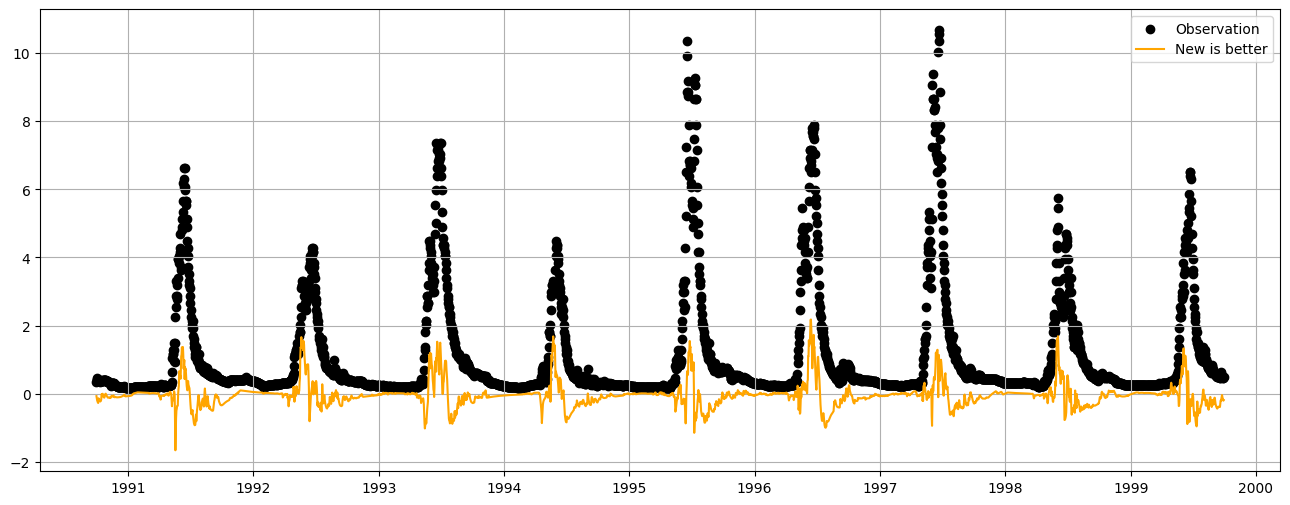

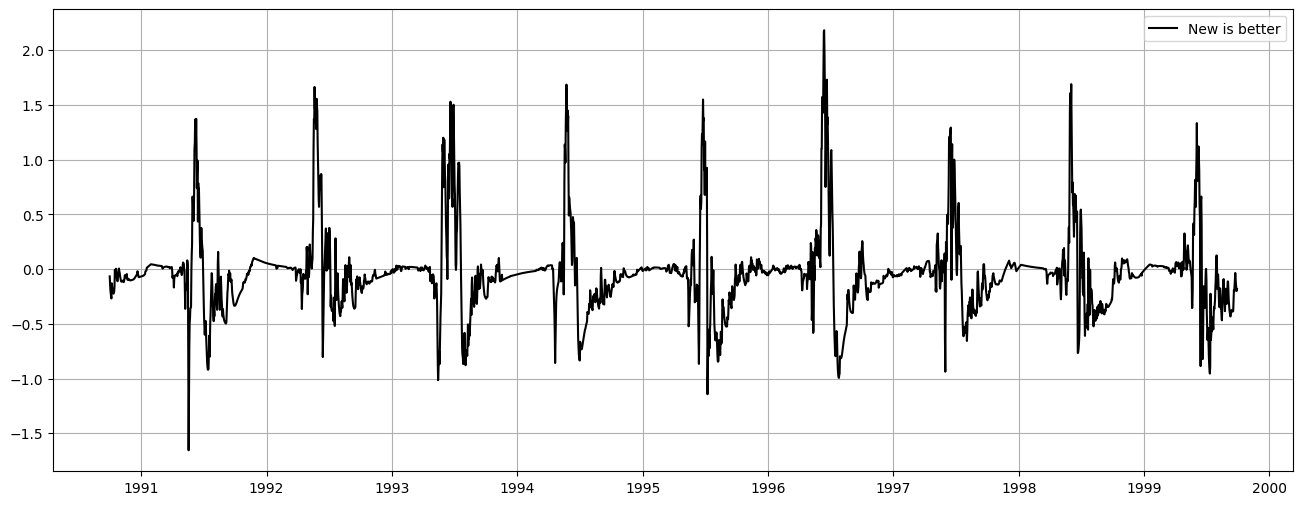

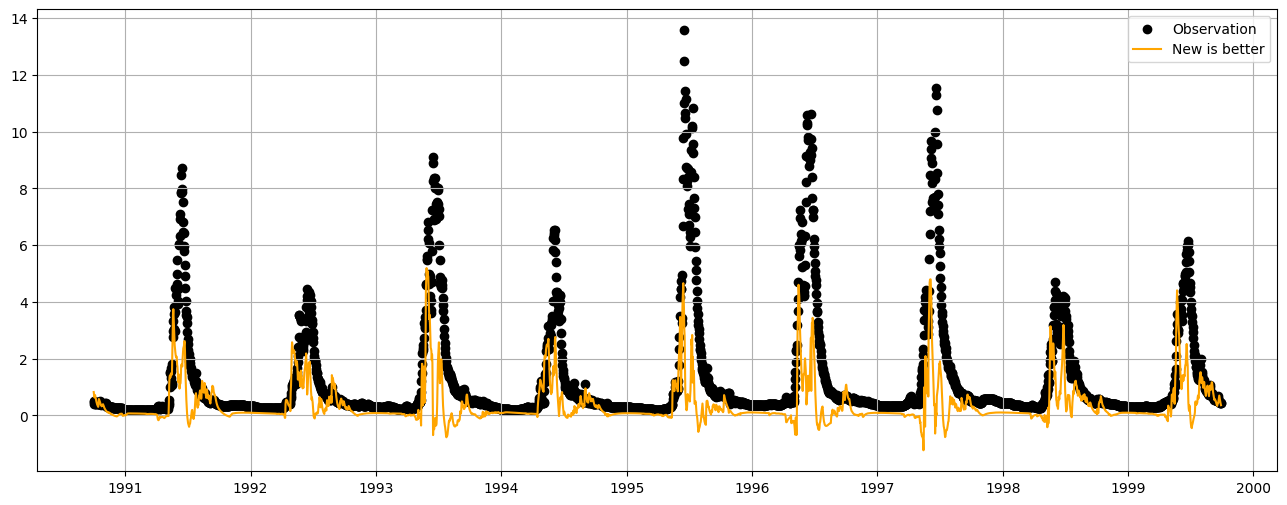

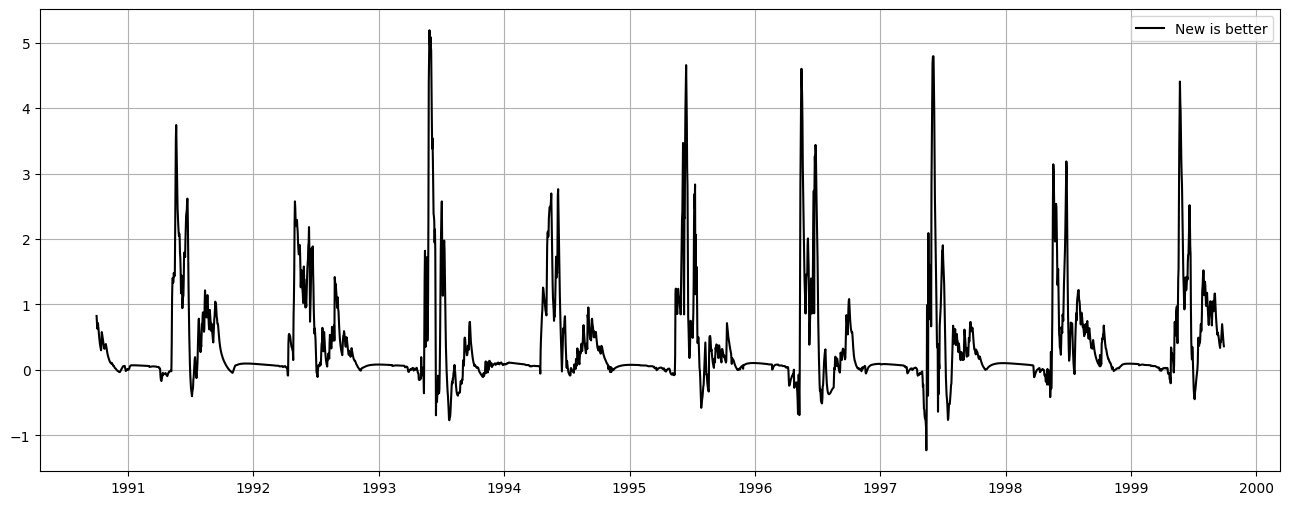

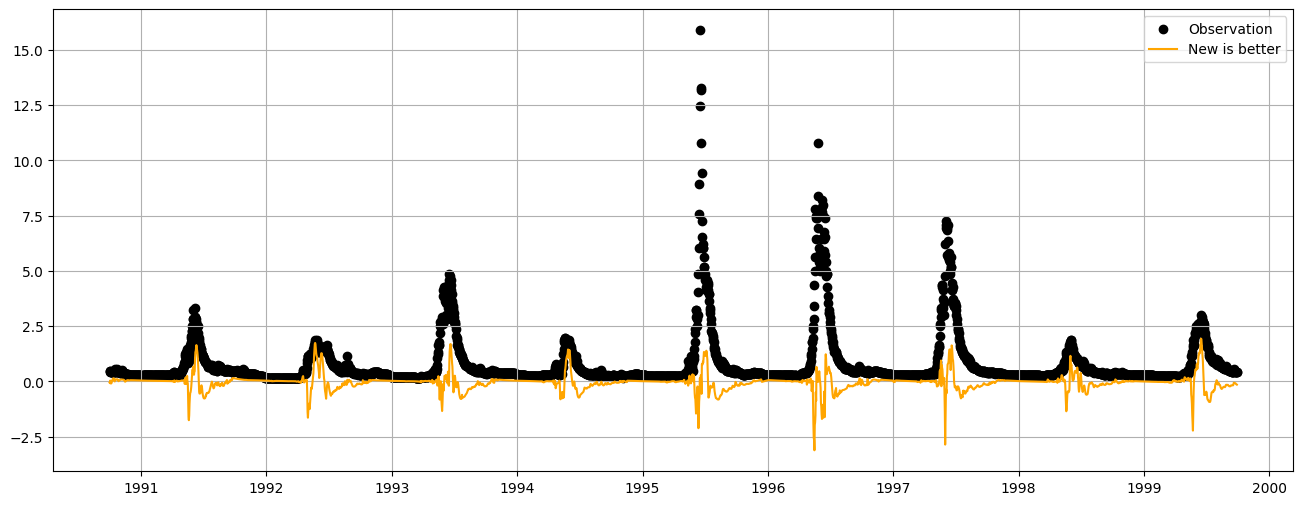

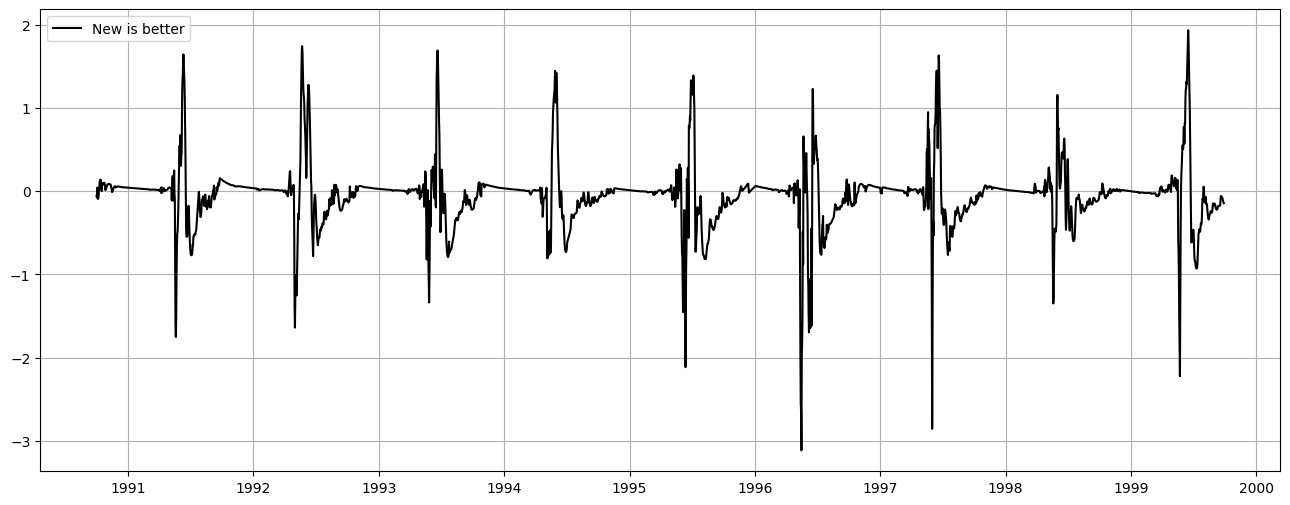

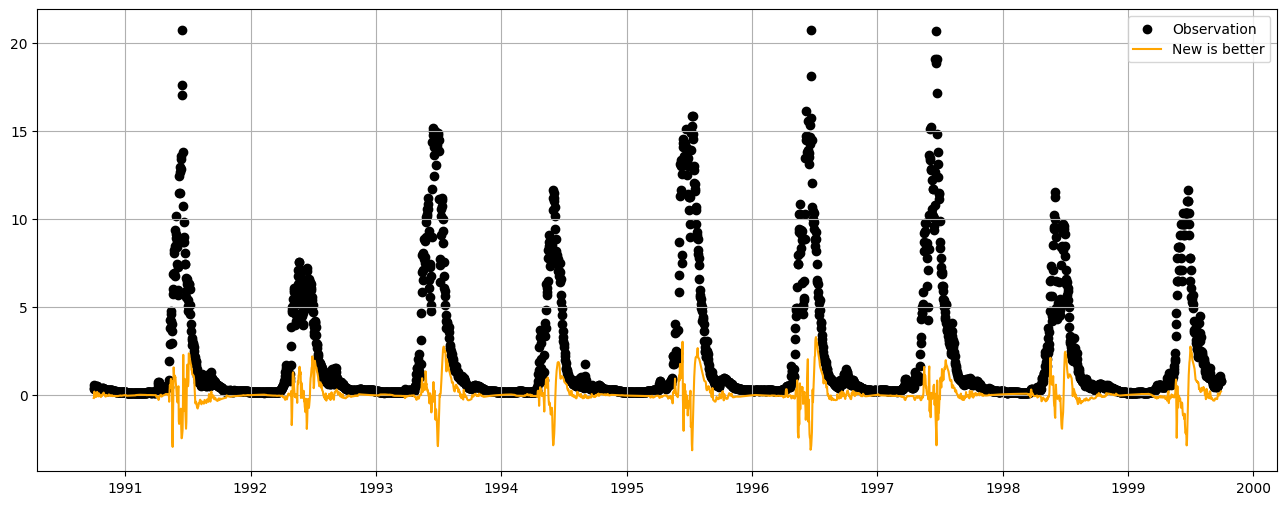

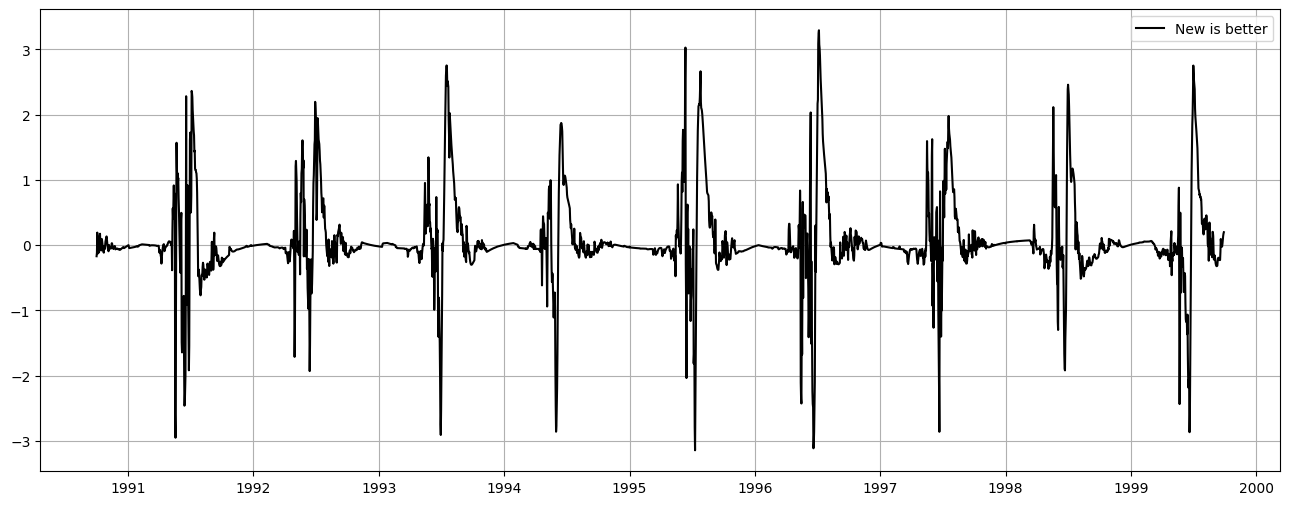

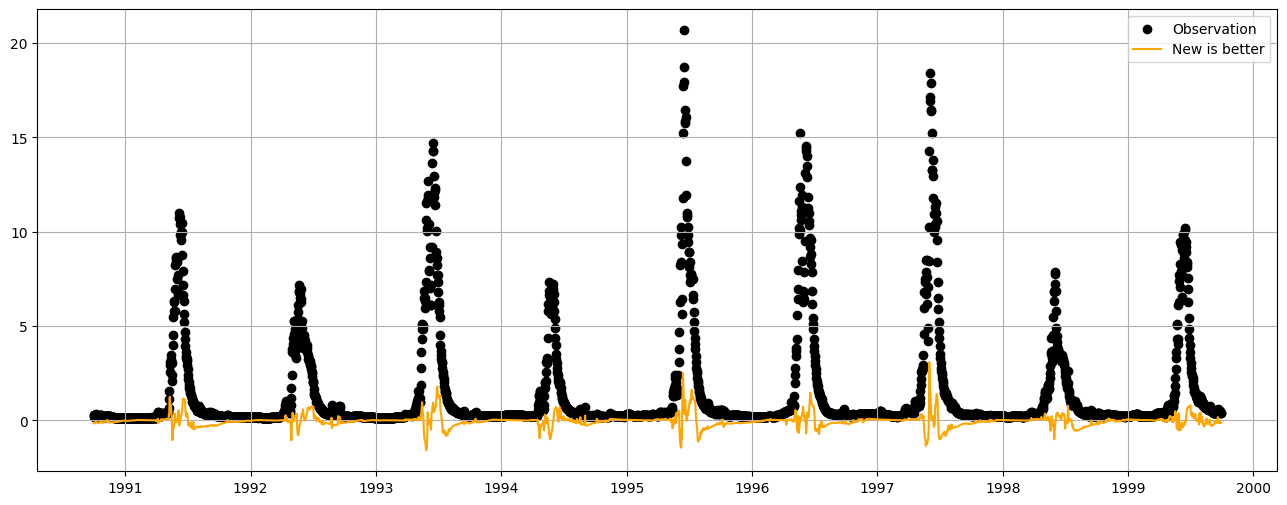

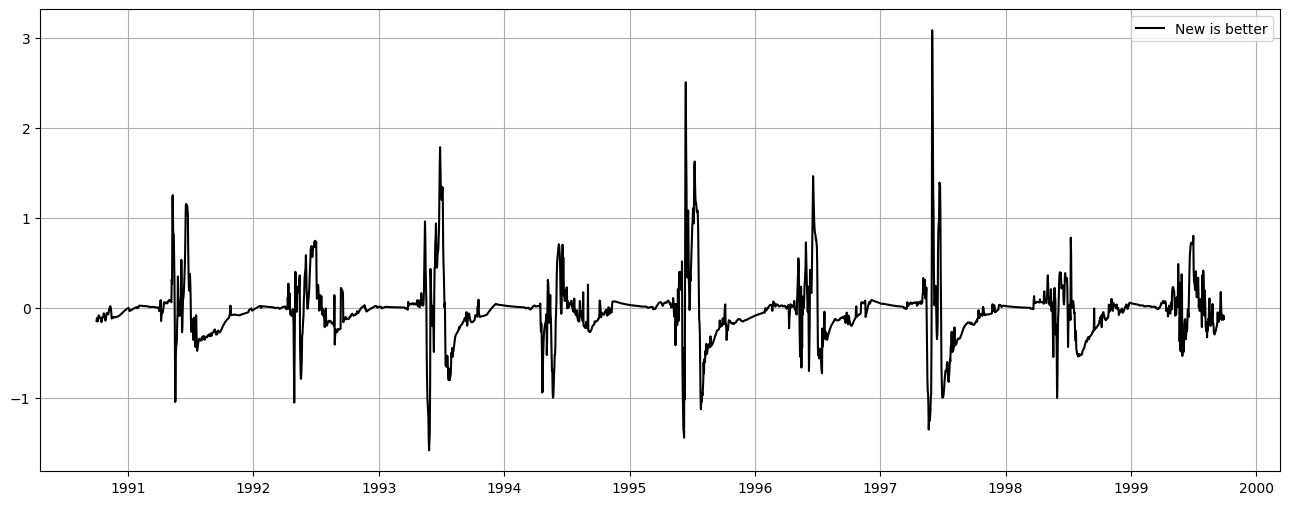

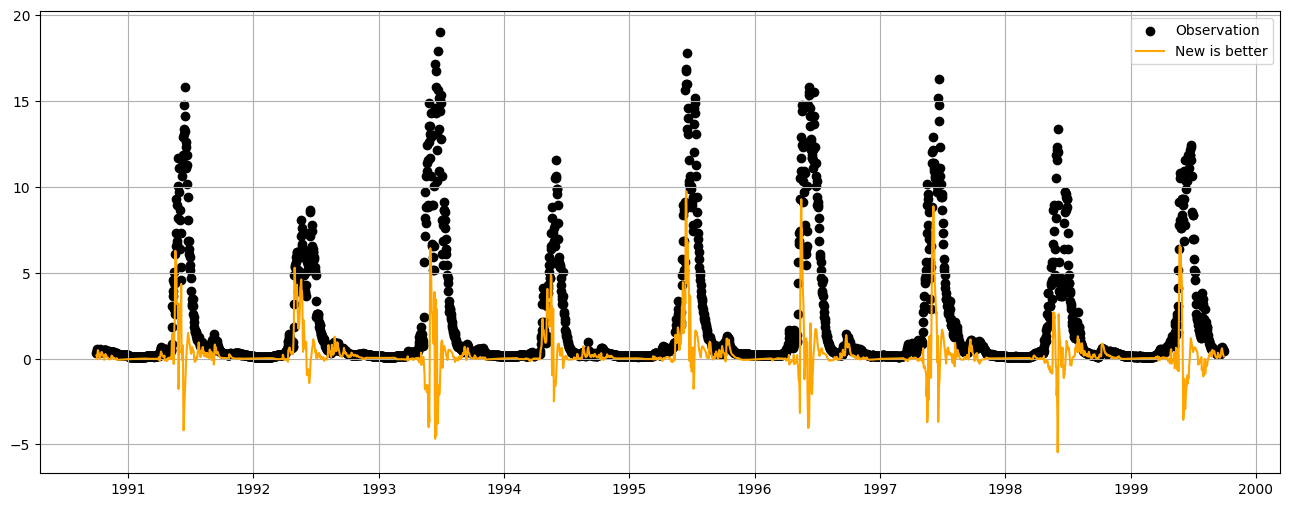

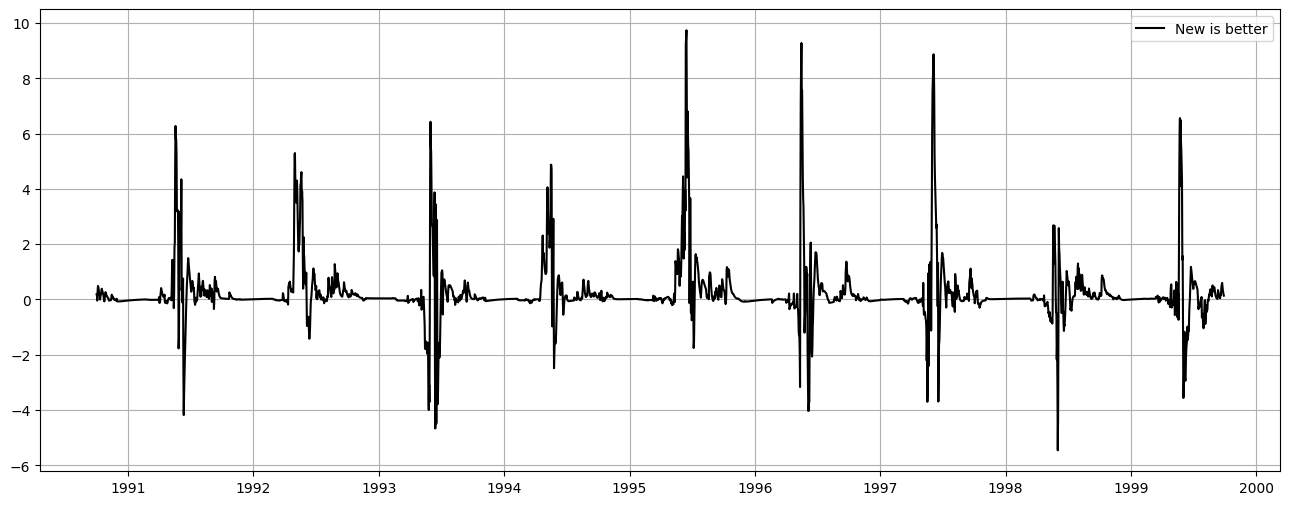

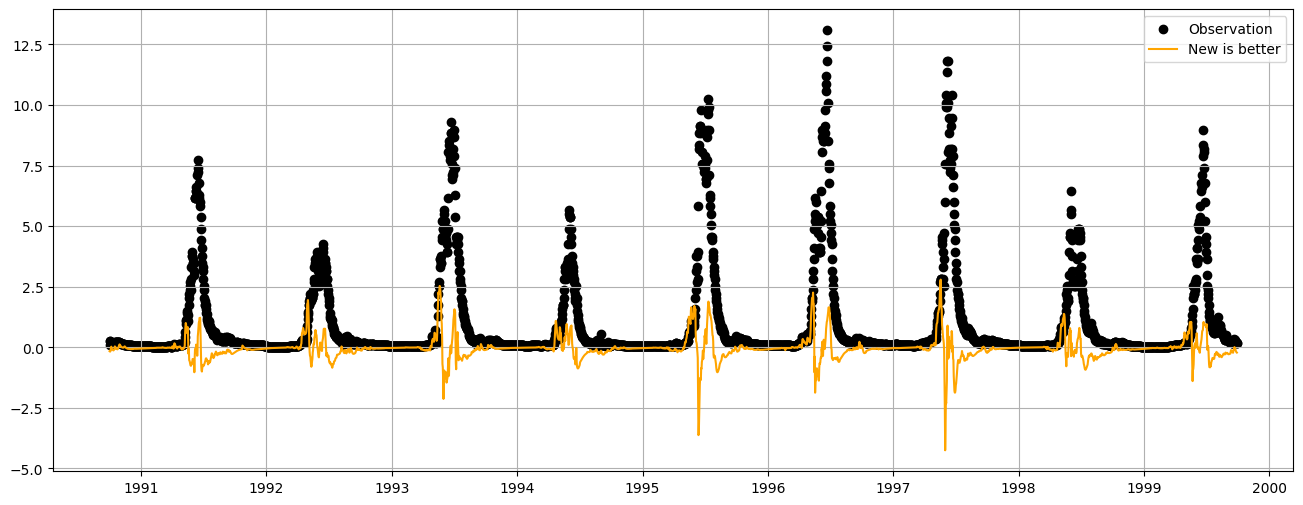

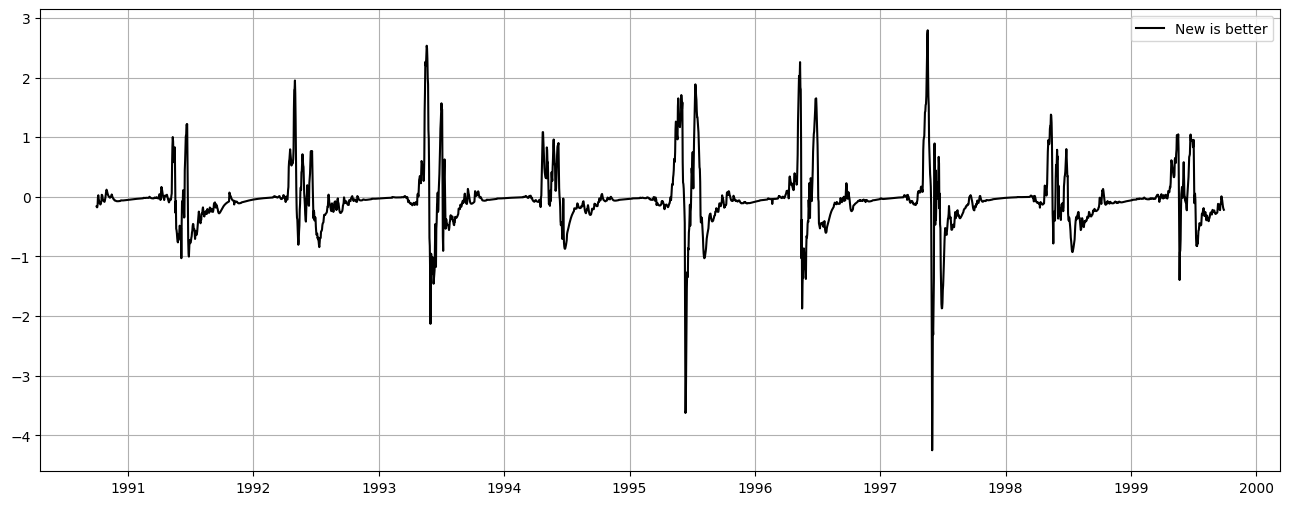

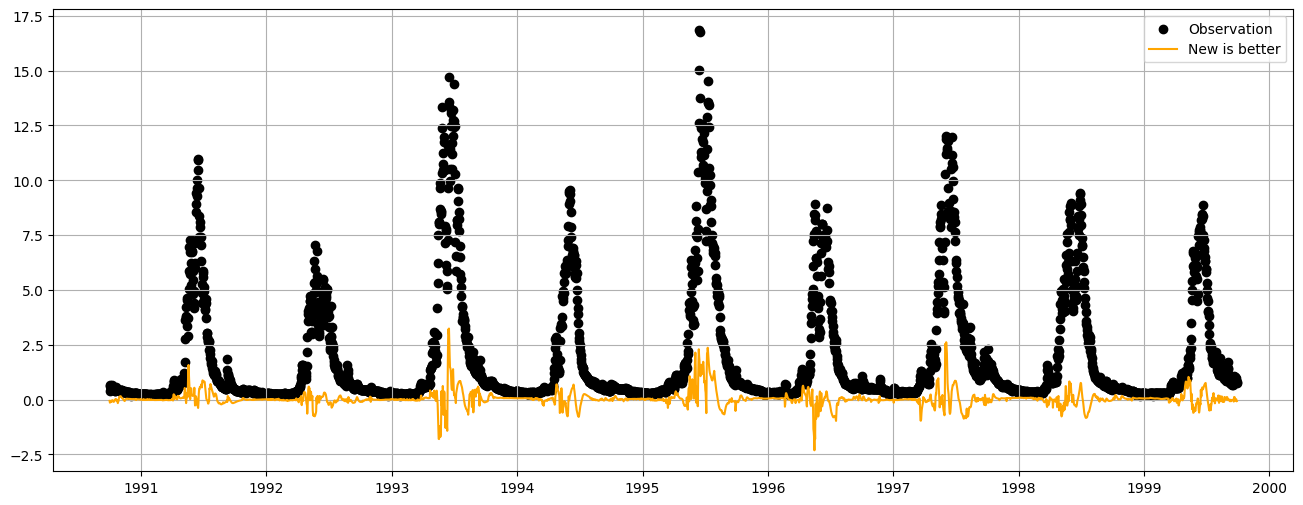

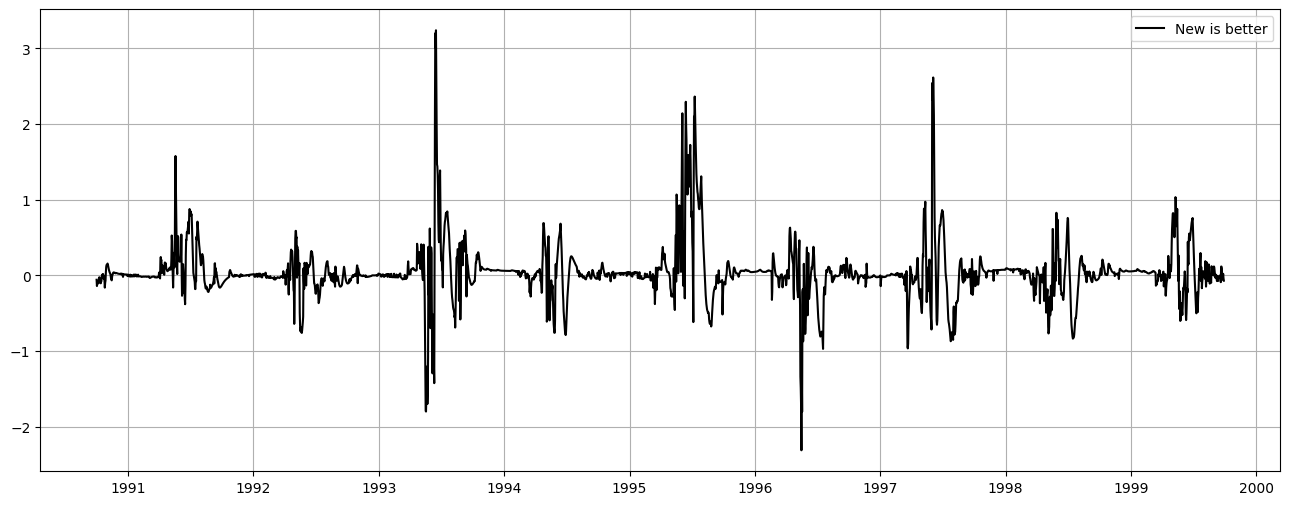

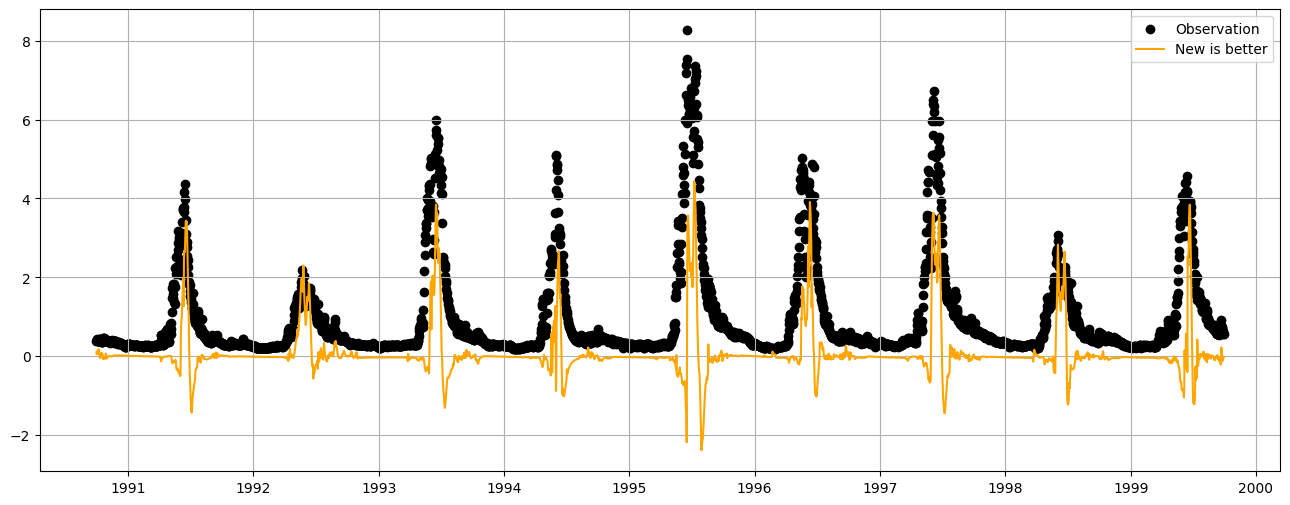

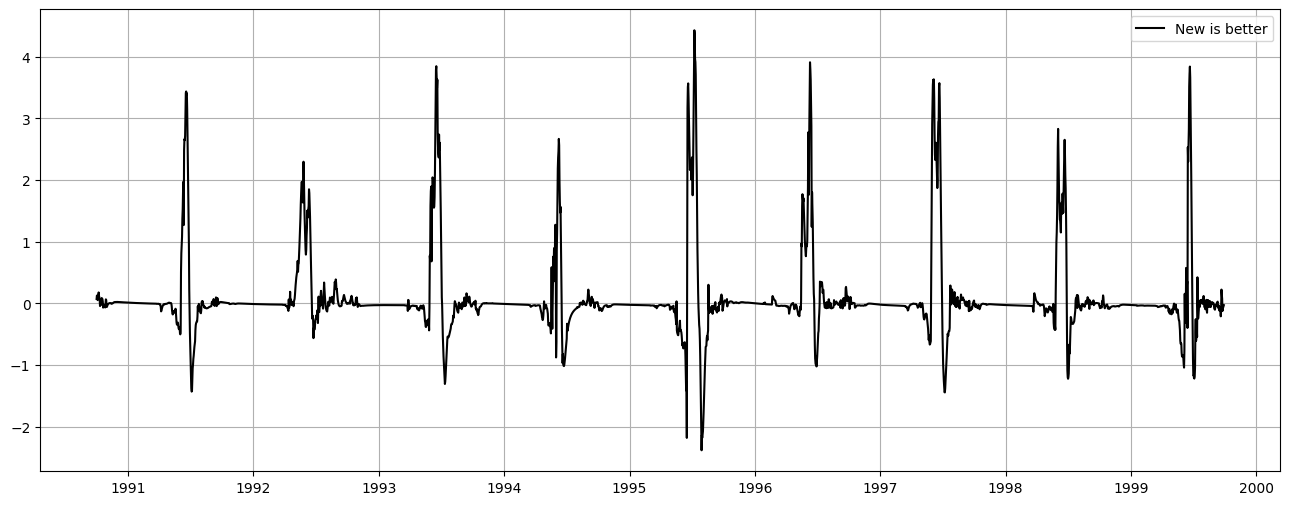

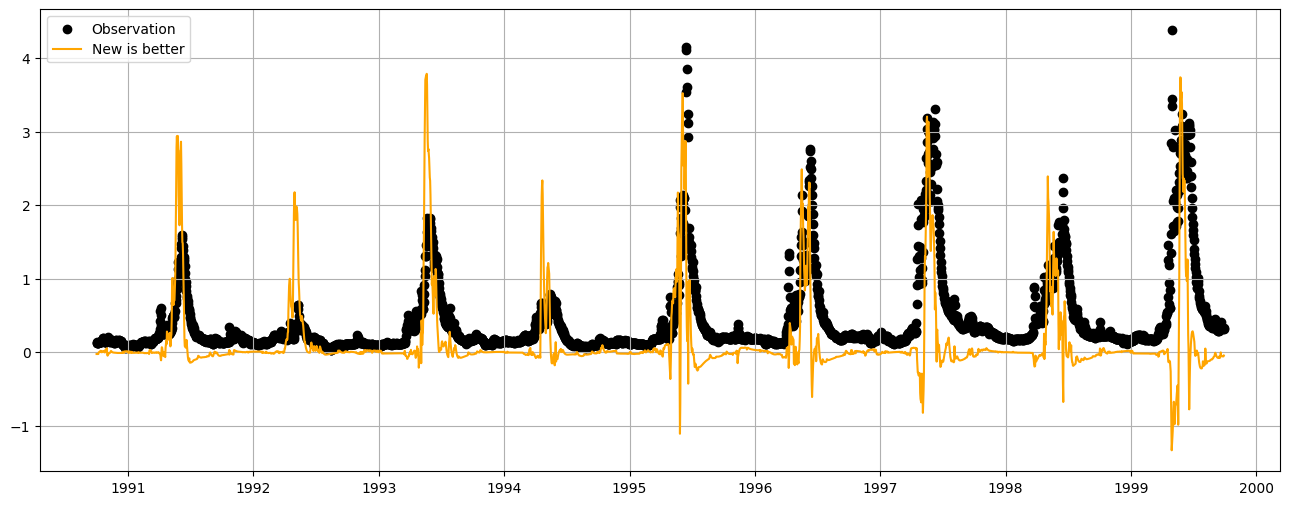

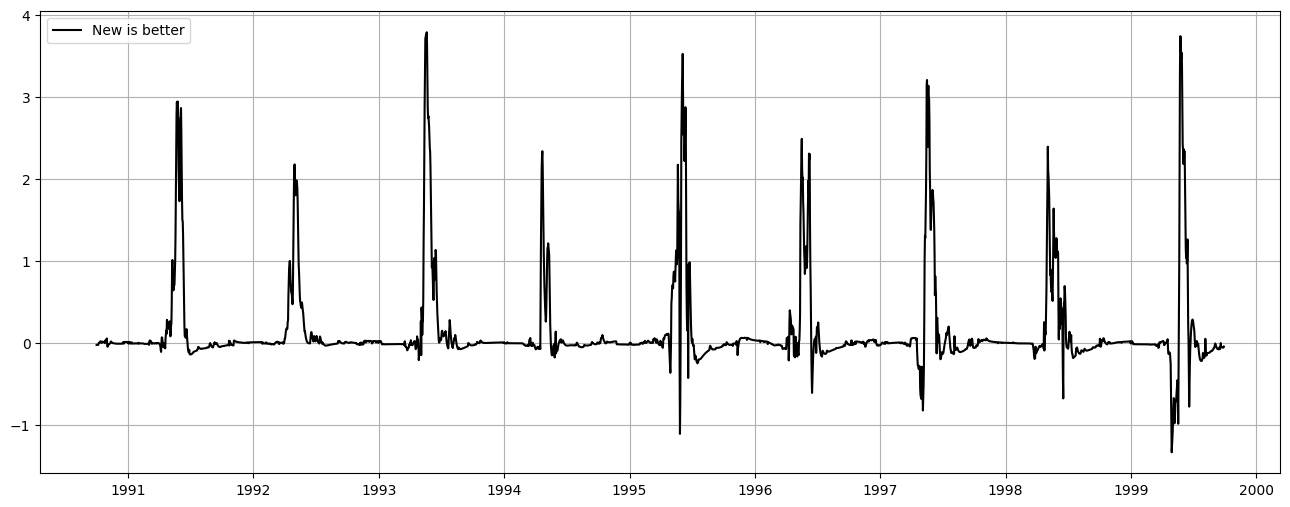

In [30]:
import matplotlib.pyplot as plt
import pandas as pd

for j in range(10):
    ob= obs_flow[:,j].tolist()
    of= sim_old[:,j].tolist()
    nf= sim_new[:,j].tolist()
    df= pd.DataFrame({'Observation':ob, 'Single Objective': of, 'Multi Objective': nf})
    df['Time']= pd.date_range(start='1990-10-01', end='1999-09-29', freq='D')
    df.set_index('Time',inplace=True)

    df['Single_error']= abs(df['Observation']-df['Single Objective'])
    df['Multi_error']= abs(df['Observation']-df['Multi Objective'])
    df['Multi_better']= (df['Single_error']- df['Multi_error'])
    plt.figure(figsize=(16,6))
    plt.scatter( df.index,df['Observation'],label='Observation', color='black')
    # plt.plot(df['Single Objective'],color='red',label= "Single Objective")
    plt.plot(df['Multi_better'],color='orange',label= "New is better")

    # plt.plot(df['Single_error'],color='red',label= "Single Objective")
    # plt.plot(df['Multi Objective'],color='blue',label= "Multi Objective")
    plt.legend()
    plt.grid()
    plt.show()

    plt.figure(figsize=(16,6))
    plt.plot(df['Multi_better'],color='black',label= "New is better")
    plt.legend()
    plt.grid()
    plt.show()

In [31]:
df

,Observation,Single Objective,Multi Objective,Single_error,Multi_error,Multi_better
Time,,,,,,
1990-10-01,0.135132,0.135615,0.161367,0.000483,0.026235,-0.025752
1990-10-02,0.122848,0.133287,0.159187,0.010440,0.036340,-0.025900
1990-10-03,0.122848,0.130839,0.156938,0.007992,0.034090,-0.026098
1990-10-04,0.122848,0.128237,0.154558,0.005390,0.031711,-0.026321
1990-10-05,0.122848,0.126541,0.152480,0.003693,0.029632,-0.025939
...,...,...,...,...,...,...
1999-09-25,0.325546,0.341895,0.399598,0.016349,0.074052,-0.057702
1999-09-26,0.313261,0.335272,0.393564,0.022011,0.080302,-0.058291
1999-09-27,0.325546,0.329578,0.387867,0.004032,0.062321,-0.058288


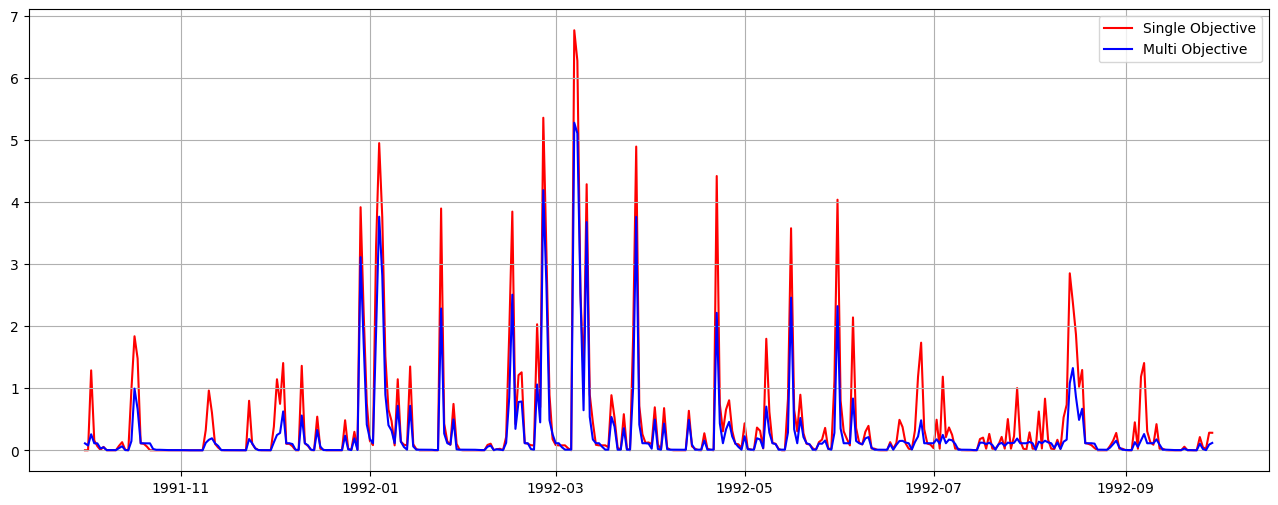

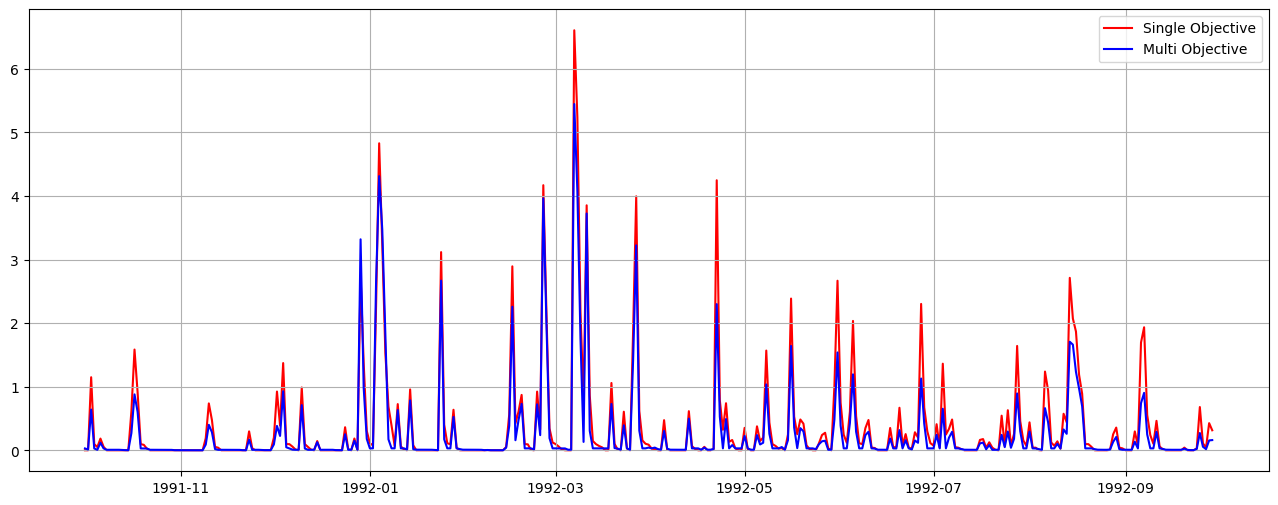

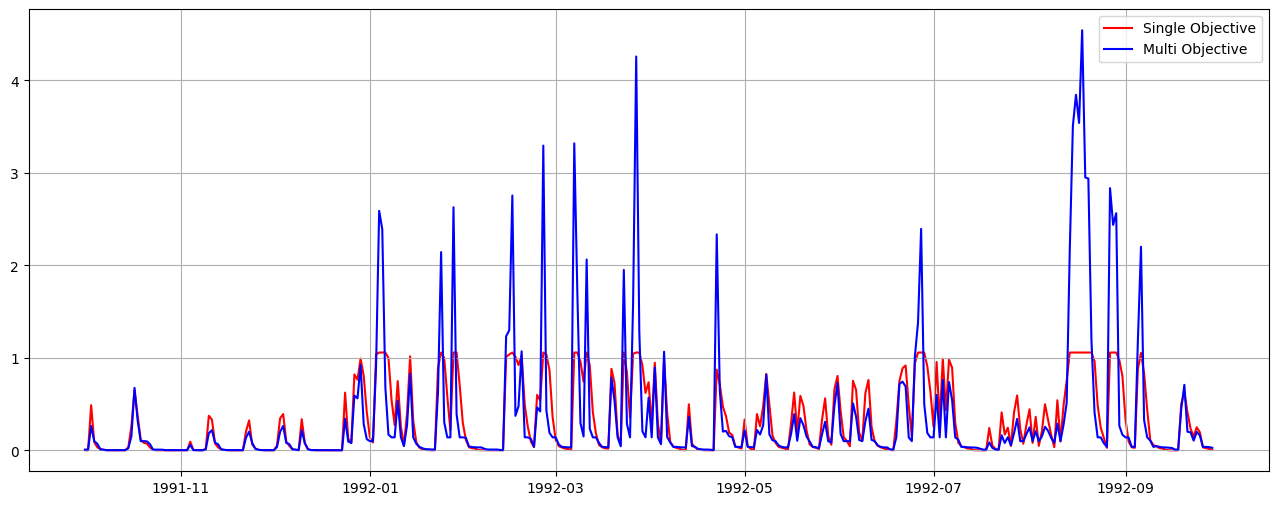

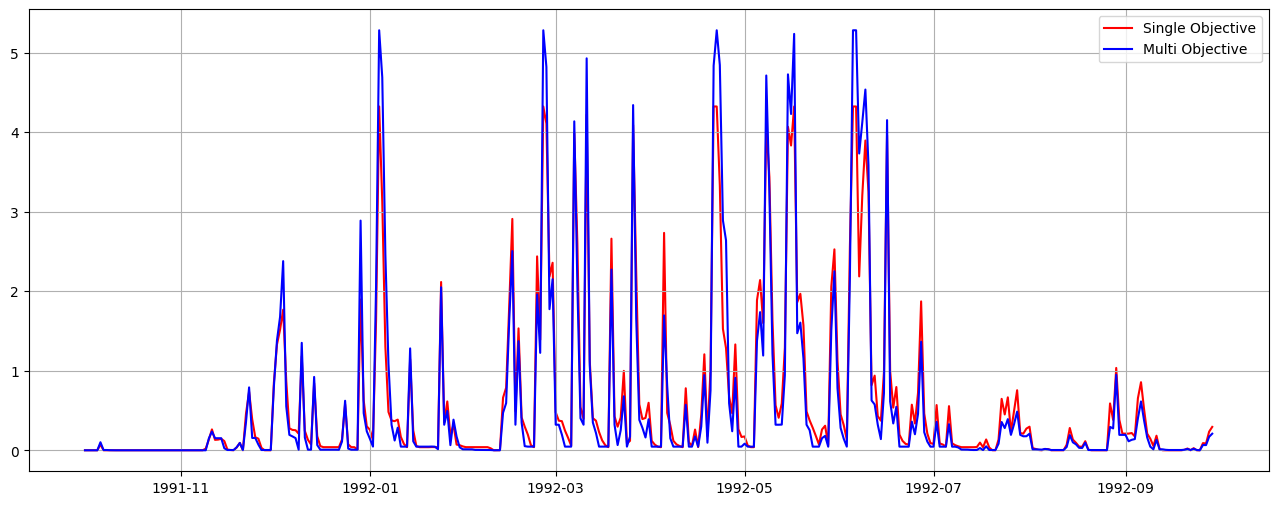

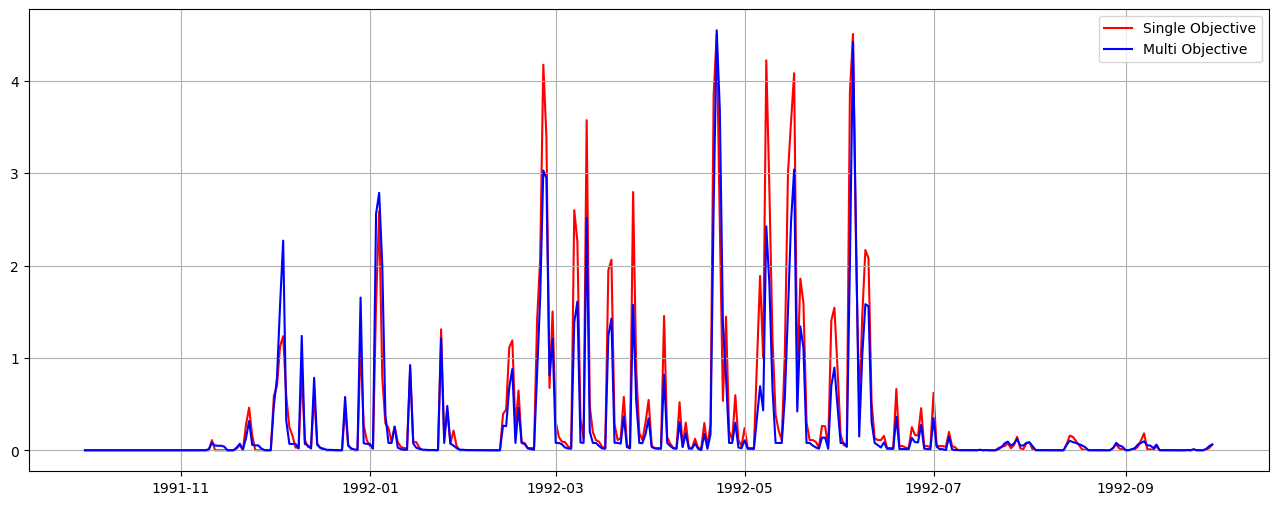

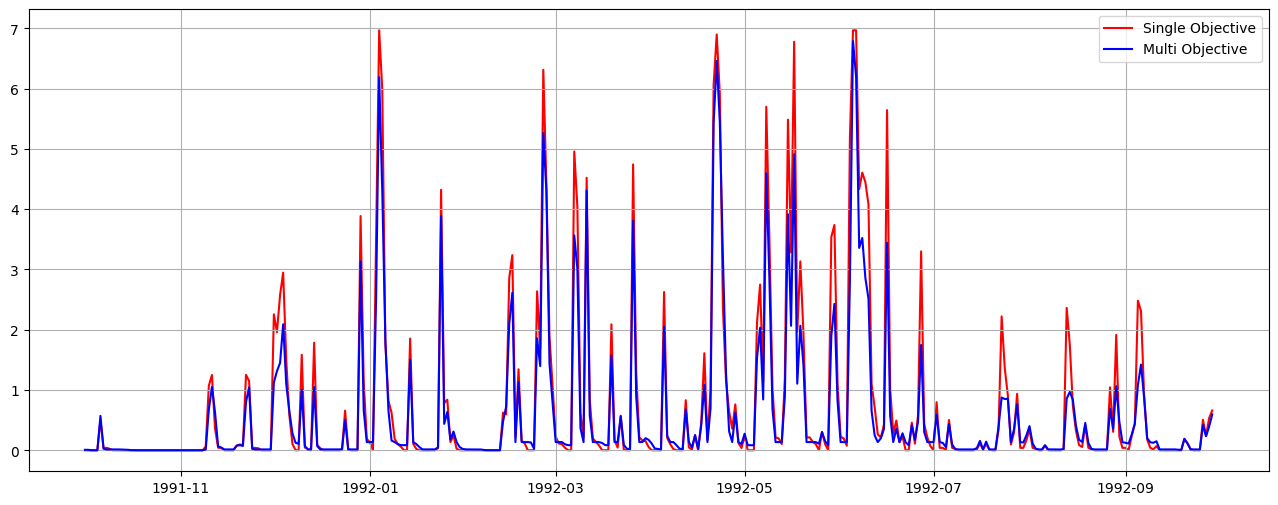

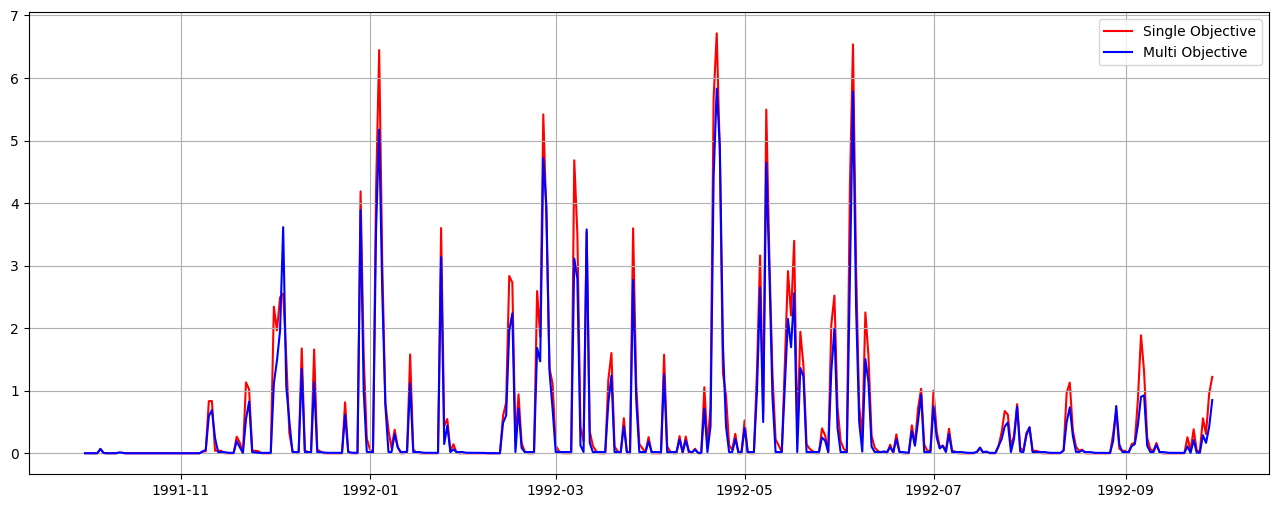

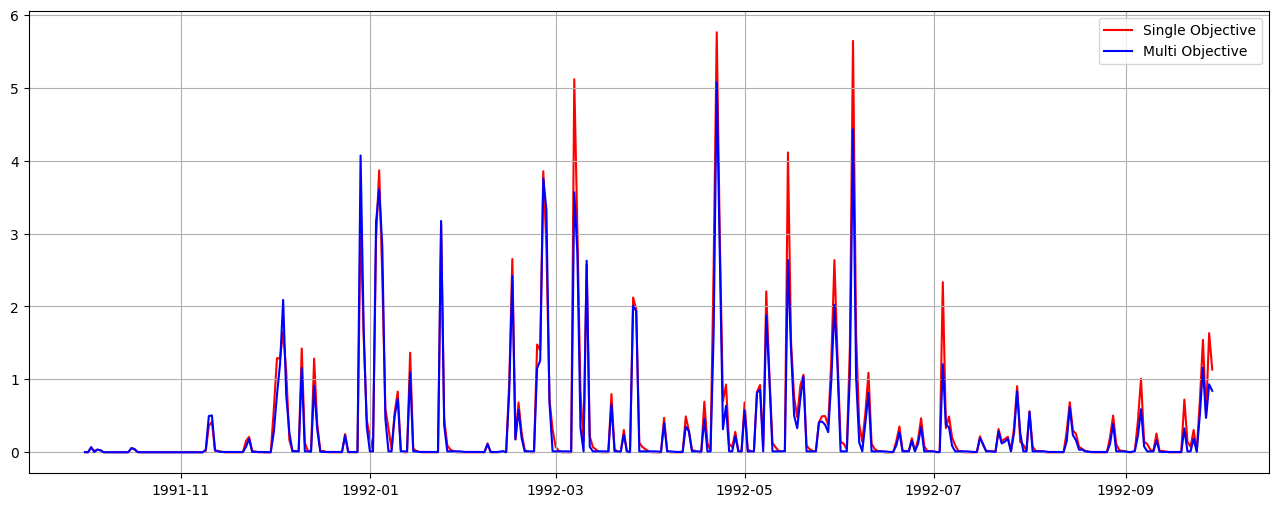

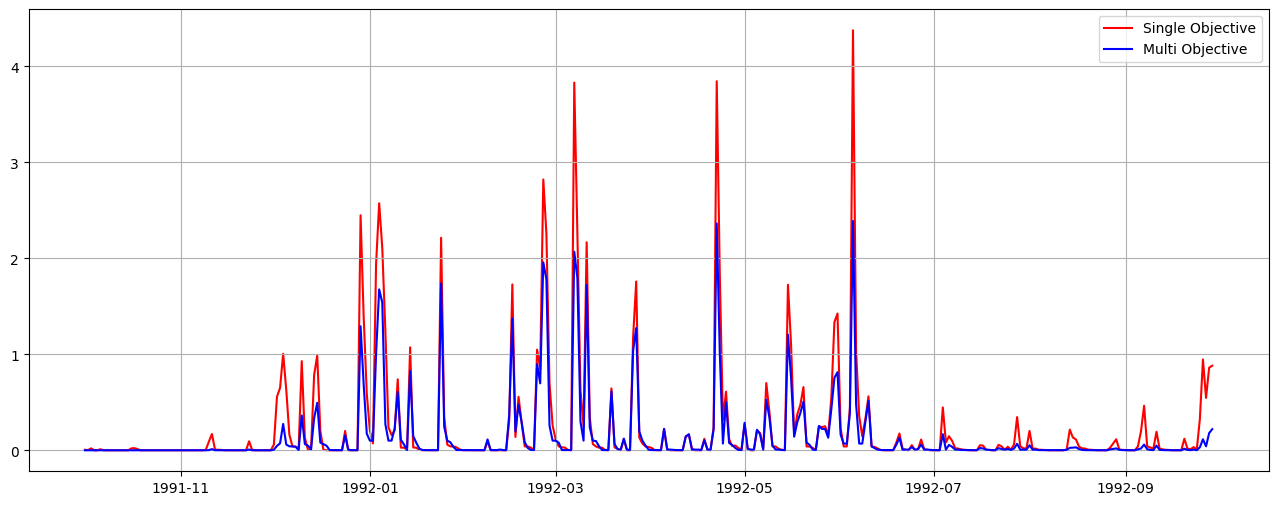

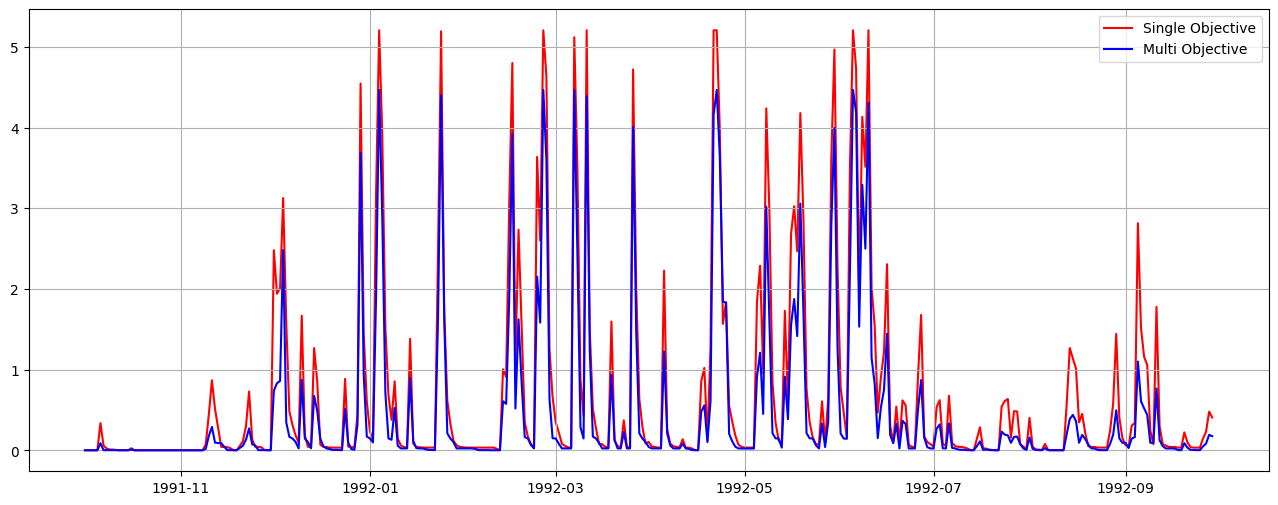

In [49]:
ps= np.load("/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_2/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/percolation.npy")
pm = np.load("/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_2/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/percolation.npy")
ps= ps.squeeze()
pm= pm.squeeze()

import matplotlib.pyplot as plt
import pandas as pd

for j in range(10):
    pml= pm[:,j].tolist()
    psl= ps[:,j].tolist()
    df= pd.DataFrame({'Single Objective': psl, 'Multi Objective': pml})
    df['Time']= pd.date_range(start='1990-10-01', end='1999-09-29', freq='D')
    df.set_index('Time',inplace=True)
    df= df[365:730]
    # df['Single_error']= abs(df['Observation']-df['Single Objective'])
    # df['Multi_error']= abs(df['Observation']-df['Multi Objective'])
    # df['Multi_better']= (df['Single_error']- df['Multi_error'])
    plt.figure(figsize=(16,6))
    # plt.scatter( df.index,df['Observation'],label='Observation', color='black')
    plt.plot(df['Single Objective'],color='red',label= "Single Objective", zorder=1)
    # plt.plot(df['Multi_better'],color='orange',label= "New is better")

    # plt.plot(df['Single_error'],color='red',label= "Single Objective")
    plt.plot(df['Multi Objective'],color='blue',label= "Multi Objective")
    plt.legend()
    plt.grid()
    plt.show()

    # plt.figure(figsize=(16,6))
    # plt.plot(df['Multi_better'],color='black',label= "New is better")
    # plt.legend()
    # plt.grid()
    # plt.show()



In [2]:
import numpy as np
import pandas as pd

forcings= np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")


df= pd.read_excel("/home/s0shar47/scratch/salil/GAGES-2/gagesII_mar1_2013_conterm.xlsx",sheet_name='Hydro')
df= pd.DataFrame(df.set_index('STAID')['BFI_AVE'])
df.reset_index(inplace=True)
print(forcings.shape)
print(df.columns)

(671, 12784, 16)
Index(['STAID', 'BFI_AVE'], dtype='object')


In [15]:
import numpy as np
import json
import pandas as pd
import os

# Read BFI values from GAGES-II
df = pd.read_excel(
    "/home/s0shar47/scratch/salil/GAGES-2/gagesII_mar1_2013_conterm.xlsx",
    sheet_name="Hydro"
)

# Keep only required columns
df = df[["STAID", "BFI_AVE"]]

# Ensure STAID is integer
df["STAID"] = df["STAID"].astype(int)

# Dictionary for fast lookup
bfi_dict = dict(zip(df["STAID"], df["BFI_AVE"]))

for i in range(1, 11):

    folder = f"/home/s0shar47/scratch/Daymet_Folds/{i}/test"

    attr_file = os.path.join(folder, "daymet_19800101_20141231_attr_671.npy")
    gage_file = os.path.join(folder, "gageid.npy")
    json_file = os.path.join(folder, "daymet_19800101_20141231_attr_671_name.json")

    attr = np.load(attr_file)
    gage = np.load(gage_file).astype(int)

    with open(json_file, "r") as f:
        attr_names = json.load(f)

    print(f"Fold {i}")
    print("Original attr shape:", attr.shape)

    # Get BFI values in the same order as gage
    bfi = np.array([bfi_dict.get(g, np.nan) for g in gage], dtype=float)

    # Check for missing gauges
    missing = np.isnan(bfi)
    if missing.any():
        print(f"Warning: {missing.sum()} gauges missing BFI values")
        print(gage[missing])

    # Append as new attribute
    attr_new = np.column_stack((attr, bfi))

    # Update attribute names
    if "BFI_AVE" not in attr_names:
        attr_names.append("BFI_AVE")

    print("New attr shape:", attr_new.shape)

    # Save
    np.save(attr_file, attr_new)

    with open(json_file, "w") as f:
        json.dump(attr_names, f, indent=4)

    print("Saved.\n")

Fold 1
Original attr shape: (52, 35)
New attr shape: (52, 36)
Saved.

Fold 2
Original attr shape: (54, 35)
New attr shape: (54, 36)
Saved.

Fold 3
Original attr shape: (52, 35)
New attr shape: (52, 36)
Saved.

Fold 4
Original attr shape: (51, 35)
New attr shape: (51, 36)
Saved.

Fold 5
Original attr shape: (54, 35)
New attr shape: (54, 36)
Saved.

Fold 6
Original attr shape: (47, 35)
New attr shape: (47, 36)
Saved.

Fold 7
Original attr shape: (56, 35)
New attr shape: (56, 36)
Saved.

Fold 8
Original attr shape: (55, 35)
New attr shape: (55, 36)
Saved.

Fold 9
Original attr shape: (54, 35)
New attr shape: (54, 36)
Saved.

Fold 10
Original attr shape: (56, 35)
New attr shape: (56, 36)
Saved.



In [3]:
df

,STAID,BFI_AVE
0,1011000,49.74094
1,1013500,53.61105
2,1015800,51.95444
3,1016500,52.06449
4,1017000,52.19897
...,...,...
9062,394308105413800,68.43523
9063,394839104570300,43.71770
9064,401733105392404,66.99432
9065,402114105350101,65.25297


In [ ]:
import numpy as np
import pandas as pd

# Load forcings
forcings = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
)

# Load BFI values
df = pd.read_excel(
    "/home/s0shar47/scratch/salil/GAGES-2/gagesII_mar1_2013_conterm.xlsx",
    sheet_name="Hydro"
)

# Create mapping: STAID -> BFI_AVE
bfi_dict = dict(zip(df["STAID"].astype(int), df["BFI_AVE"]))

print("Original shape:", forcings.shape)

# Gauge IDs (same for every timestep)
gauge_ids = forcings[:, 0, -2].astype(int)

# Update last variable (BFI_AVE)
missing = []

for i, gid in enumerate(gauge_ids):
    if gid in bfi_dict:
        forcings[i, :, -1] = bfi_dict[gid]
    else:
        missing.append(gid)

print(f"Matched gauges : {len(gauge_ids) - len(missing)}")
print(f"Missing gauges : {len(missing)}")

if missing:
    print("Missing STAIDs:")
    print(missing)

# # Save updated array
# np.save(
#     "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_bfi.npy",
#     forcings,
# )
forcings
import json

file_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_name.json"
with open(file_path, "r") as f:
            data = json.load(f)

        # # append new entry
data.append("BFI_AVE")
with open(f"/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_bfi_name.json", "w") as f:
            json.dump(data, f)

# Save updated array
np.save(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_bfi.npy",
    forcings,
)

Original shape: (671, 12784, 16)
Matched gauges : 671
Missing gauges : 0


In [ ]:
import numpy as np
import pandas as pd
import os
import shutil
# -----------------------------
# Load data properly
# -----------------------------
updated_forcings = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_LocalHYSEP_mmday.npy"
)

attr = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy"
)

df = pd.read_csv("/scratch/data/CAMELS_531.csv")
df["Gauge ID"] = df["Gauge ID"].astype(str).str.zfill(8)

# Gauge IDs from forcing
gauge_id = updated_forcings[:, 0, -2].astype(int).astype(str)
gauge_id = np.char.zfill(gauge_id, 8)

all_idx = np.arange(updated_forcings.shape[0])

# -----------------------------
# PUR regions
# -----------------------------
regionDivide = [
    [1, 2],
    [3, 6],
    [4, 5, 7],
    [9, 10],
    [8, 11, 12, 13],
    [14, 15, 16, 18],
    [17]
]

base_filename = "daymet_19800101_20141231_forcing_671_LocalHYSEP_mmday.npy"
attr_filename = "daymet_19800101_20141231_attr_671.npy"

root = "/scratch/data/PUR_DATA/"

for i, hucs in enumerate(regionDivide, start=1):

    # -----------------------------
    # TEST indices (531 subset)
    # -----------------------------
    region_gauges = df[df["HUC"].isin(hucs)]["Gauge ID"].values
    test_idx = np.where(np.isin(gauge_id, region_gauges))[0]

    # -----------------------------
    # TRAIN indices (671 full set minus test)
    # -----------------------------
    train_idx = np.setdiff1d(all_idx, test_idx)

    # -----------------------------
    # Split forcing
    # -----------------------------
    train_forcing = updated_forcings[train_idx]
    test_forcing = updated_forcings[test_idx]

    # -----------------------------
    # Split attributes
    # -----------------------------
    train_attr = attr[train_idx]
    test_attr = attr[test_idx]

    # -----------------------------
    # Directories
    # -----------------------------
    train_dir = os.path.join(root, "train", f"Region_{i}")
    test_dir  = os.path.join(root, "test", f"Region_{i}")

    os.makedirs(train_dir, exist_ok=True)
    os.makedirs(test_dir, exist_ok=True)

    # -----------------------------
    # Save forcing
    # -----------------------------
    np.save(os.path.join(train_dir, base_filename), train_forcing)
    np.save(os.path.join(test_dir, base_filename), test_forcing)

    # -----------------------------
    # Save attributes
    # -----------------------------
    np.save(os.path.join(train_dir, attr_filename), train_attr)
    np.save(os.path.join(test_dir, attr_filename), test_attr)
    # JSON files to copy
# -----------------------------
    forcing_json = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_LocalHYSEP_mmday_name.json"
    attr_json    = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671_name.json"

    # -----------------------------
    # Copy to TRAIN folder
    # -----------------------------
    shutil.copy(forcing_json, train_dir)
    shutil.copy(attr_json, train_dir)

    # -----------------------------
    # Copy to TEST folder
    # -----------------------------
    shutil.copy(forcing_json, test_dir)
    shutil.copy(attr_json, test_dir)

    print(
        f"Region {i}: "
        f"Train={train_forcing.shape[0]}, Test={test_forcing.shape[0]}"
    )

Region 1: Train=579, Test=92
Region 2: Train=576, Test=95
Region 3: Train=578, Test=93
Region 4: Train=620, Test=51
Region 5: Train=603, Test=68
Region 6: Train=611, Test=60
Region 7: Train=599, Test=72


: 

In [20]:
import baseflow

print(dir(baseflow))

['Backward', 'Boughton', 'CM', 'Chapman', 'EWMA', 'Eckhardt', 'Fixed', 'Fixed_interpolation', 'Furey', 'KGE', 'LH', 'Local', 'Local_turn', 'Path', 'Slide', 'Slide_interpolation', 'UKIH', 'UKIH_turn', 'Willems', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'clean_streamflow', 'comparision', 'example', 'exist_ice', 'format_method', 'geo2imagexy', 'hysep_interval', 'linear_interpolation', 'maxmium_BFI', 'methods', 'moving_average', 'multi_arange', 'njit', 'np', 'param_calibrate', 'param_calibrate_jit', 'param_estimate', 'pd', 'prange', 'recession_coefficient', 'recession_period', 'separation', 'single', 'strict_baseflow', 'tqdm', 'utils']


In [21]:
import baseflow
import inspect

functions = [
    name for name, obj in inspect.getmembers(baseflow, inspect.isfunction)
]

print(functions)

['Fixed', 'KGE', 'Local', 'Slide', 'UKIH', 'clean_streamflow', 'exist_ice', 'format_method', 'geo2imagexy', 'hysep_interval', 'maxmium_BFI', 'moving_average', 'njit', 'param_calibrate', 'recession_coefficient', 'recession_period', 'separation', 'single', 'strict_baseflow']


In [22]:
ar

,area
0,4.03
1,5.38
2,5.54
3,6.12
4,7.75
...,...
666,10598.19
667,12654.96
668,12849.71
669,14268.92
